# Sensitivity of $(E, \nu, h_i)$ to the fixed constants $h_w$, $\rho_i$, $\rho_w$

The same cached grid inversion as `step3_invert_fixed.ipynb`, repeated with one fixed constant changed at a time while the other two stay at the baseline:

| swept | range | step |
|---|---|---|
| $h_w$ | 8.0–12.0 m | 0.25 m |
| $\rho_i$ | 870–940 kg/m³ (first-year sea ice) | 10 kg/m³ |
| $\rho_w$ | 1000–1030 kg/m³ (fresh water to Chukchi seawater, ≈1024–1027 at S≈31–33, T≈−1.7 °C) | 5 kg/m³ |

Differences from `step3_invert_fixed.ipynb`:

* **Narrower grid, same spacing.** E 2.5–7.5 GPa and h_i 0.85–1.15 m at ΔE = 0.05 GPa, Δν = 0.005, Δh_i = 0.005 m: 101 × 81 × 61 nodes.
* **FG cache band 5–50 Hz**, which covers every FG pick (5.0–50.0 Hz).
* **FG cache.** `build_fg_cache` solves the FG dispersion relation for every grid node at once (Newton steps safeguarded by bisection); P and SH are closed form and evaluated directly at the picks. A scenario takes ~20 s.

Each scenario's cache is built in memory (~17 s) and not saved. Each scenario's global posterior and per-event summaries go to `sensitivity_fixed/runs/`. A finished scenario is reused on re-run unless the events, σ, grid or bands have changed, or `RERUN = True`.

In [1]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.special import logsumexp

from das_tools.hammer_inversion import (
    load_events, ParameterGrid, grid_param_names,
    set_wave_sigmas,
    build_fg_cache,
    invert_cached, standardized_residuals,
)
from das_tools.utils import proj_path

plt.rcParams.update({
    "font.size": 16,          # base size
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 16,
})
mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{times}",
})

In [2]:
# Each sweep varies one constant and holds the other two here.
BASELINE = dict(h_w=10.0, rho_i=910.0, rho_w=1025.0, P=0.0)

SWEEPS = {
    "h_w":   np.round(np.arange(8.0, 12.0 + 1e-9, 0.25), 2),   # m
    "rho_i": np.arange(870.0, 940.0 + 1e-9, 10.0),              # kg/m^3
    "rho_w": np.arange(1000.0, 1030.0 + 1e-9, 5.0),             # kg/m^3
}

bounds = [(2.5e9, 7.5e9), (0.05, 0.45), (0.85, 1.15)]
grid = ParameterGrid.from_bounds(
    bounds[0], bounds[1], bounds[2],
    n_E=101,     # ΔE = 0.05 GPa
    n_nu=81,     # Δν = 0.005
    n_h_i=61,    # Δh_i = 0.005 m
)

FG_BAND = (5.0, 50.0)
FG_FREQUENCY = np.arange(FG_BAND[0], FG_BAND[1] + 0.5, 1.0)   # FG cache grid, 1 Hz

# Inputs and outputs live under outputs/tap_inv_batch/ in the project
# (das_tools.utils.proj_path; DAS_LFI_OUTPUT_DIR moves it).
OUT = proj_path.output_dir("tap_inv_batch")
EVENTS_FILE = OUT / "dispersion_events_0908_clean.npz"   # outliers removed by step2_residual_diagnostics.ipynb
OUT_DIR = OUT / "sensitivity_fixed"
FIG_SUP = proj_path.figures_dir("supplementary")
FIG_DIR = FIG_SUP / "S6_hammer_inv_sensitivity"
RERUN = False

PARAMS = grid_param_names(grid)
for sub in ("runs", "figures"):
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

In [3]:
events = load_events(EVENTS_FILE)

Loaded 23 events from:
/Users/junsuj/Desktop/git/das-landfast-ice-inversion2025/outputs/tap_inv_batch/dispersion_events_0908_clean.npz


In [4]:
SIGMA_BY_WAVE = {"P": 0.0124*np.sqrt(2.83), 
                 "SH": 0.0292*np.sqrt(4.68), 
                 "FG": 0.0168*np.sqrt(7.84)}
print(SIGMA_BY_WAVE)

events = set_wave_sigmas(events, SIGMA_BY_WAVE)

{'P': np.float64(0.020860028763163296), 'SH': np.float64(0.06316925834612909), 'FG': np.float64(0.04703999999999999)}


In [5]:
# Everything besides the constants that changes the likelihood. A saved scenario is
# reused only if this and its constants (h_w, rho_i, rho_w, P) both match.
RUN_CONFIG = json.loads(json.dumps(dict(
    events_file=EVENTS_FILE.name,
    bounds=bounds,
    grid_size={p: len(getattr(grid, p)) for p in PARAMS},
    fg_frequency=FG_FREQUENCY.tolist(),
    fg_band=FG_BAND,
    sigma_by_wave=SIGMA_BY_WAVE,
)))


def scenario_label(c):
    return f"h_w={c['h_w']:g}_rho_i={c['rho_i']:g}_rho_w={c['rho_w']:g}"


scenarios = {scenario_label(BASELINE): dict(BASELINE)}
for name, values in SWEEPS.items():
    for v in values:
        c = dict(BASELINE, **{name: float(v)})
        scenarios.setdefault(scenario_label(c), c)

print(f"{len(scenarios)} unique scenarios on a {' x '.join(str(len(getattr(grid, p))) for p in PARAMS)} grid")

30 unique scenarios on a 101 x 81 x 61 grid


In [6]:
def summarize(constants, event_results, global_result, cache):
    label = scenario_label(constants)
    row = {"scenario": label, **constants}
    for p in PARAMS:
        marg = global_result.marginals[p]
        lo, hi = global_result.marginal_credible_interval(p, level=0.95)
        row.update({
            f"{p}_MAP": global_result.map_params[p],
            f"{p}_mean": global_result.marginal_mean(p),
            f"{p}_std": global_result.marginal_std(p),
            f"{p}_ci_lo": lo,
            f"{p}_ci_hi": hi,
            # Marginal mass on the two outermost nodes: more than ~1% means the bounds cut the posterior.
            f"{p}_edge_mass": float((marg[0] + marg[-1]) / marg.sum()),
        })
    # Same data and σ in every scenario, so these compare across scenarios.
    # log_evidence is the marginal likelihood under a uniform prior on the grid box.
    logp = global_result.log_posterior
    row["max_logL"] = global_result.map_log_posterior
    row["log_evidence"] = float(logsumexp(logp) - np.log(logp.size))

    resid = pd.DataFrame(standardized_residuals(events, cache=cache, result=global_result))
    for wt, d in resid.groupby("wave"):
        row[f"chi2_per_point_{wt}"] = float(np.mean(d["r"] ** 2))

    event_rows = []
    for event in events:
        r = event_results[event.event_id]
        er = {"scenario": label, **constants, "event_id": event.event_id, "waves": "+".join(sorted(event.waves))}
        for p in PARAMS:
            axis = r.parameter_axes[p]
            er.update({
                f"{p}_MAP": r.map_params[p],
                f"{p}_mean": r.marginal_mean(p),
                f"{p}_std": r.marginal_std(p),
                f"{p}_MAP_on_edge": bool(np.isclose(r.map_params[p], axis[0]) or np.isclose(r.map_params[p], axis[-1])),
            })
        event_rows.append(er)
    return row, event_rows


def save_run(label, row, event_rows, global_result):
    meta = {"config": RUN_CONFIG, "summary": row, "events": event_rows}
    np.savez_compressed(
        OUT_DIR / "runs" / f"{label}.npz",
        # log posterior relative to its maximum; float32 keeps full precision near the peak
        logp_rel=(global_result.log_posterior - global_result.map_log_posterior).astype(np.float32),
        **{f"axis_{p}": global_result.parameter_axes[p] for p in PARAMS},
        **{f"marginal_{p}": global_result.marginals[p] for p in PARAMS},
        metadata=np.array(json.dumps(meta, default=lambda o: o.item() if hasattr(o, "item") else str(o))),
    )


def load_run(label, constants):
    path = OUT_DIR / "runs" / f"{label}.npz"
    if RERUN or not path.exists():
        return None
    with np.load(path, allow_pickle=False) as d:
        meta = json.loads(d["metadata"].item())
        # The label omits P, so compare every constant, not just the file name.
        stored = {k: meta["summary"].get(k) for k in constants}
        if meta["config"] != RUN_CONFIG or stored != constants:
            return None
        marginals = {p: d[f"marginal_{p}"] for p in PARAMS}
    return meta["summary"], meta["events"], marginals

In [7]:
summary_rows, event_rows, marginals = [], [], {}
t_start = time.time()
for i, (label, constants) in enumerate(scenarios.items(), 1):
    saved = load_run(label, constants)
    if saved is not None:
        row, ev_rows, marginals[label] = saved
        print(f"[{i}/{len(scenarios)}] {label}: loaded")
    else:
        t0 = time.time()
        # Built in memory (~17 s); finished scenarios are reloaded from runs/ instead.
        cache = build_fg_cache(grid, constants, FG_FREQUENCY)
        event_results, global_result = invert_cached(events, grid, cache)
        row, ev_rows = summarize(constants, event_results, global_result, cache)
        save_run(label, row, ev_rows, global_result)
        marginals[label] = dict(global_result.marginals)
        del cache, event_results, global_result
        print(f"[{i}/{len(scenarios)}] {label}: {time.time() - t0:.0f} s")
    summary_rows.append(row)
    event_rows.extend(ev_rows)
print(f"total {(time.time() - t_start) / 60:.1f} min")

summary = pd.DataFrame(summary_rows)
event_summary = pd.DataFrame(event_rows)
summary.to_csv(OUT_DIR / "sensitivity_summary.csv", index=False)
event_summary.to_csv(OUT_DIR / "sensitivity_events.csv", index=False)

[1/30] h_w=10_rho_i=910_rho_w=1025: loaded
[2/30] h_w=8_rho_i=910_rho_w=1025: loaded
[3/30] h_w=8.25_rho_i=910_rho_w=1025: loaded
[4/30] h_w=8.5_rho_i=910_rho_w=1025: loaded
[5/30] h_w=8.75_rho_i=910_rho_w=1025: loaded
[6/30] h_w=9_rho_i=910_rho_w=1025: loaded
[7/30] h_w=9.25_rho_i=910_rho_w=1025: loaded
[8/30] h_w=9.5_rho_i=910_rho_w=1025: loaded
[9/30] h_w=9.75_rho_i=910_rho_w=1025: loaded
[10/30] h_w=10.25_rho_i=910_rho_w=1025: loaded
[11/30] h_w=10.5_rho_i=910_rho_w=1025: loaded
[12/30] h_w=10.75_rho_i=910_rho_w=1025: loaded
[13/30] h_w=11_rho_i=910_rho_w=1025: loaded
[14/30] h_w=11.25_rho_i=910_rho_w=1025: loaded
[15/30] h_w=11.5_rho_i=910_rho_w=1025: loaded
[16/30] h_w=11.75_rho_i=910_rho_w=1025: loaded
[17/30] h_w=12_rho_i=910_rho_w=1025: loaded
[18/30] h_w=10_rho_i=870_rho_w=1025: loaded
[19/30] h_w=10_rho_i=880_rho_w=1025: loaded
[20/30] h_w=10_rho_i=890_rho_w=1025: loaded
[21/30] h_w=10_rho_i=900_rho_w=1025: loaded
[22/30] h_w=10_rho_i=920_rho_w=1025: loaded
[23/30] h_w=10_rh

In [8]:
def sweep_rows(df, name):
    # One sweep: `name` varies, the other two at baseline. Includes the baseline itself.
    others = [c for c in SWEEPS if c != name]
    m = np.all([np.isclose(df[c], BASELINE[c]) for c in others], axis=0)
    return df[m].sort_values(name)

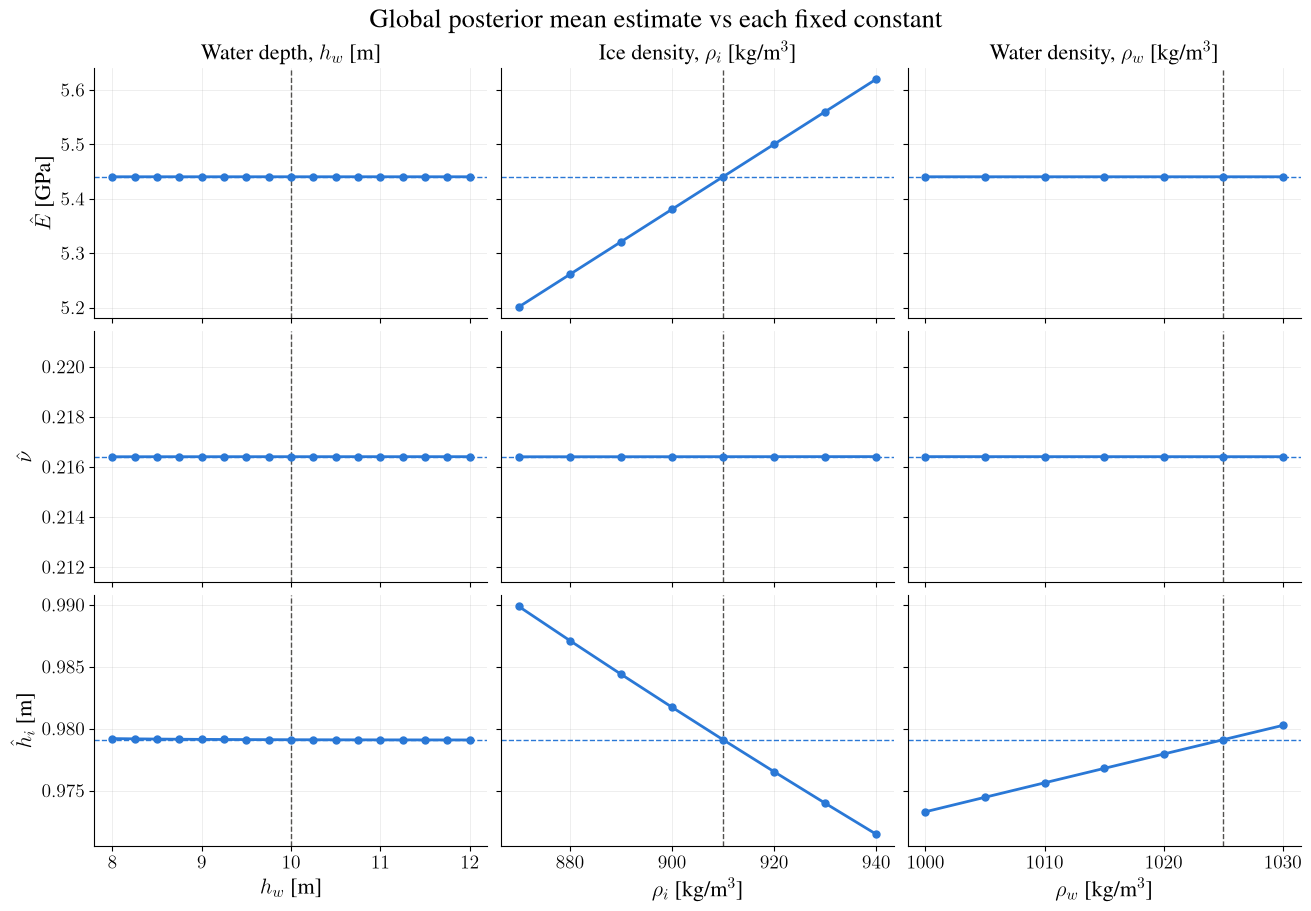

In [9]:

BLUE, GRAY, INK = "#2a78d6", "#8f8e88", "#52514e"
SWEEP_LABELS = {
    "h_w": "Water depth, $h_w$ [m]",
    "rho_i": r"Ice density, $\rho_i$ [kg/m$^3$]",
    "rho_w": r"Water density, $\rho_w$ [kg/m$^3$]",
}
SWEEP_X_LABELS = {
    "h_w": r"$h_w$ [m]",
    "rho_i": r"$\rho_i$ [kg/m$^3$]",
    "rho_w": r"$\rho_w$ [kg/m$^3$]",
}
ESTIMATE_LABELS = {
    "E": r"$\hat{E}$ [GPa]",
    "nu": r"$\hat{\nu}$",
    "h_i": r"$\hat{h}_{i}$ [m]",
}
SCALE = {"E": 1e9}


def style(ax):
    ax.grid(alpha=0.3, lw=0.5)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

base = summary.set_index("scenario").loc[scenario_label(BASELINE)]

# Global posterior mean against the value of each fixed constant.
# Dashed lines: the baseline value of the constant (vertical) and the reported estimate,
# i.e. the baseline posterior mean (horizontal). Rows share a y-axis so the three constants can be
# compared on the same scale.
fig, axes = plt.subplots(len(PARAMS), len(SWEEPS), figsize=(13, 9), sharex="col", sharey="row",
                         constrained_layout=True)
for j, s in enumerate(SWEEPS):
    sub = sweep_rows(summary, s)
    for i, p in enumerate(PARAMS):
        ax, k = axes[i, j], SCALE.get(p, 1.0)
        ax.axvline(BASELINE[s], color=INK, ls="--", lw=1)
        ax.axhline(base[f"{p}_mean"] / k, color=BLUE, ls="--", lw=1)
        ax.plot(sub[s], sub[f"{p}_mean"] / k, color=BLUE, lw=2, marker="o", ms=5)
        style(ax)
    axes[0, j].set_title(SWEEP_LABELS[s], fontsize=16)
    axes[-1, j].set_xlabel(SWEEP_X_LABELS[s])
for i, p in enumerate(PARAMS):
    k = SCALE.get(p, 1.0)
    # Span at least one grid step either side of the reported value, so a row whose
    # estimate barely moves (nu) shows as flat instead of zooming into rounding noise.
    step = np.diff(getattr(grid, p)).mean() / k
    rep = base[f"{p}_mean"] / k
    lo, hi = axes[i, 0].get_ylim()
    axes[i, 0].set_ylim(min(lo, rep - step), max(hi, rep + step))
    axes[i, 0].ticklabel_format(axis="y", useOffset=False)
    axes[i, 0].set_ylabel(ESTIMATE_LABELS[p])
fig.suptitle(f"Global posterior mean estimate vs each fixed constant")
fig.savefig(FIG_DIR / "sensitivity_global.pdf",
    format="pdf",
    dpi=200,
    bbox_inches="tight",
    pad_inches=0.2,)
plt.show()